<font size=10>Alpaca VHH Sequencing Part V</font>

<font size=5>Create an alpaca SHM Model</font>

Calculate BASELINe





https://shazam.readthedocs.io/en/stable/vignettes/Targeting-Vignette/

In [5]:
library(airr)
library(shazam)

#db1 <- read_airr("Reps/SA-S1-done-preclone.tsv")
db2 <- read_airr("blasted/SA-S1-RepOut.tsv")
db3 <- read_airr("blasted/SSA-S1-RepOut.tsv")


sub_model <- createSubstitutionMatrix(db2)

mut_model <- createMutabilityMatrix(db2, sub_model)


ERROR: Error in createSubstitutionMatrix(db2): The column germline_alignment_d_mask was not found


In [14]:

# Number of silent mutations used for estimating 5-mer mutabilities 
mut_model2@numMutS

#number of replacement mutations used for estimating 5-mer mutablities 
mut_model2@numMutR

#Mutability and source as a data.frame
head(as.data.frame(mut_model2))

#create targeting model matrix from subsitutution and mutability models
tar_matrix <- createTargetingMatrix(sub_model2, mut_model2)

[1] 14180

[1] 0

,motif,mutability,source
,<fct>,<dbl>,<fct>
AAAAA,AAAAA,0.0014425283,Inferred
AAAAC,AAAAC,0.0014425283,Inferred
AAAAG,AAAAG,0.0014425283,Inferred
AAAAT,AAAAT,0.0014425283,Inferred
AAACA,AAACA,0.0006441999,Inferred
AAACC,AAACC,0.0009039507,Measured


In [3]:
library(airr)
library(shazam)


db <- read_airr("Reps/Clones/Germ1/A-S1-germ.tsv")



#collapse sequences into clonal consensus sequences
clone_db <- collapseClones(db)

write_airr(clone_db, "Reps/Germ1/CollapsedallClones.tsv")


#create targeting model in one step using consensus sequence input and germline columns
model <- createTargetingModel(clone_db)

observed <- observedMutations(clone_db,
                             sequenceColumn="clonal_sequence",
                             germlineColumn="clonal_germline",
                             regionDefinition=IMGT_V, nproc=8)

expected <- expectedMutations(observed,
                            sequenceColumn="clonal_sequence",
                            germlineColumn="clonal_germline",
                            targetingModel=model,
                            regionDefinition=IMGT_V, nproc=8)

baseline <- calcBaseline(expected, testStatistic="focused",
                        regionDefinition=IMGT_V, nproc=8)




ERROR: Error: 'Reps/Clones/Germ1/A-S1-germ.tsv' does not exist in current working directory ('/home/troyhinkley/alpaca').


Warning message:
“It is deprecated to specify `guide = FALSE` to remove a guide. Please use `guide = "none"` instead.”
Warning message:
“It is deprecated to specify `guide = FALSE` to remove a guide. Please use `guide = "none"` instead.”


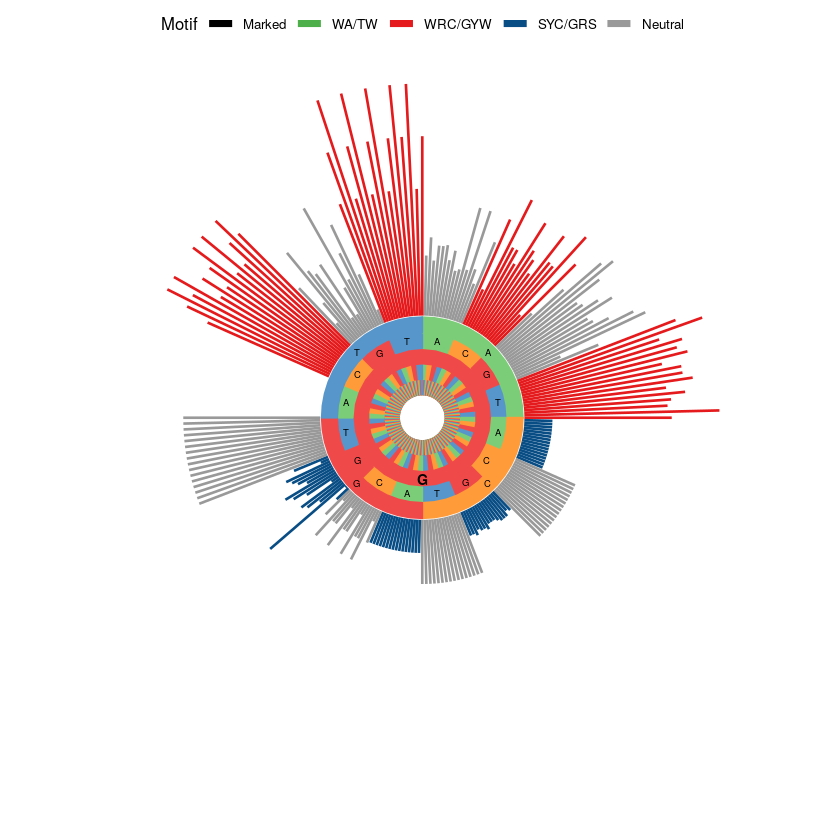

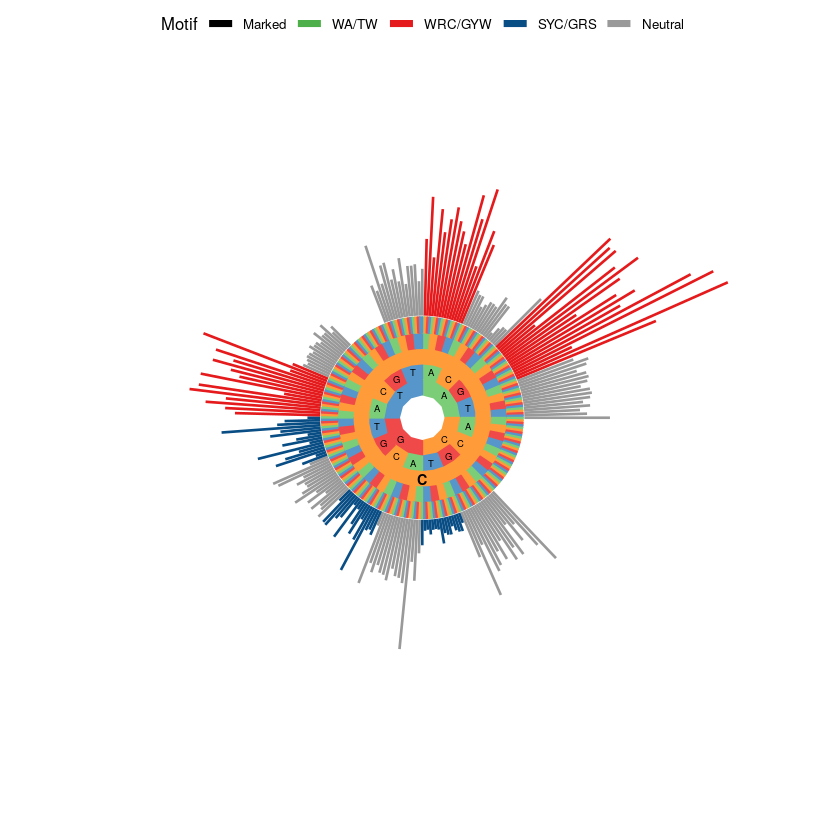

In [11]:
#generate a hedgehog plot of the mutability model
plotMutability(model, nucleotides="G", style="hedgehog")
#plotMutability(model, nucleotides="G", style="bar")

plotMutability(model, nucleotides="C", style="hedgehog")


In [31]:
dist <- calcTargetingDistance(model)

dist

,AAAAA,AAAAC,AAAAG,AAAAT,AAAAN,AAACA,AAACC,AAACG,AAACT,AAACN,⋯,NNNTA,NNNTC,NNNTG,NNNTT,NNNTN,NNNNA,NNNNC,NNNNG,NNNNT,NNNNN
A,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
C,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
G,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
T,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
N,0,0,0,0,0,0,0,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
